### Multiclass Classification
: 결과가 여러개의 클래스로 나오는 경우

#### Wine Recognition Dataset
1. 178개의 instance
2. 13개의 input feature
3. target : 'class' 내부에 3개의 품종(1,2,3)로 분류

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import *
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split

device = 'cuda' if torch.cuda.is_available() else 'cpu'

torch.manual_seed(42)

- 다중 분류 모델의 손실함수 CrossEntropyLoss 는 목푯값을 인덱스(정수)로 사용
- y의 dtype 은 long(정수형)으로 생성해야 함

In [2]:
def make_Dataset(x_train, x_val, y_train, y_val, batch_size= 32):
    x_train_ts = torch.tensor(x_train, dtype= torch.float32)
    y_train_ts = torch.tensor(y_train, dtype= torch.long)
    x_val_ts = torch.tensor(x_val, dtype= torch.float32)
    y_val_ts = torch.tensor(y_val, dtype= torch.long)

    train_dataset = TensorDataset(x_train_ts, y_train_ts)

    train_loader = DataLoader(train_dataset, batch_size= batch_size, shuffle=True)

    return train_loader, x_val_ts, y_val_ts

In [3]:
def train(dataloader, model, loss_fn, optimizer, device):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    tr_loss = 0
    
    model.train()
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        pred = model(x)
        loss = loss_fn(pred, y)
        tr_loss += loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    tr_loss /= num_batches

    return tr_loss.item()

In [4]:
def evaluate(x_val_ts, y_val_ts, model, loss_fn, device):
    model.eval()
    with torch.no_grad():
        x, y = x_val_ts.to(device), y_val_ts.to(device)
        pred = model(x)
        val_loss = loss_fn(pred, y).item()

    return val_loss, pred

In [5]:
def learning_curve(tr_loss_list, val_loss_list):
    epochs = list(range(1, len(tr_loss_list)+1))
    plt.plot(epochs, tr_loss_list, label= 'train error', marker= '.')
    plt.plot(epochs, val_loss_list, label= 'val error', marker= '.')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()

### Step 1. 데이터 불러오기 및 전처리

In [ ]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data'

columns = ['class','Alcohol','Malicacid','Ash','Alaclinity_of_ash','Magnesium','Total_phenols', 'Falvanoids','Nonflavanoid_phenols', 'Proanthocyanins', 'Color_intensity','Hue', '0D280_0D315_of_diluted_wines', 'Proline']
data = pd.read_csv(url, names= columns)
# print(data.head())
# print(len(data))

# 입력 x, 출력 y 분리
target = 'class'
x = data.drop(target, axis=1)
y = data.loc[:, target]

# 원본 클래스 1,2,3 -> 0,1,2 변환 (정수인코딩)
le = LabelEncoder()
y = le.fit_transform(y)
# print(y)
# print(type(y))          # Numpy.ndarray 로 변환되었음으로 x 스케일링 후 .values 필요 없음

# training data 8:2 로 분할
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=.2)

# 표준화 (Scaling)
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)

# 학습/테스트 인덱스 섞기, 원본 데이터 분리 (train 입력, train 출력 , test 입력, test 출력)
train_loader, x_val_ts, y_val_ts = make_Dataset(x_train, x_val, y_train, y_val, 32)

   class  Alcohol  Malicacid   Ash  Alaclinity_of_ash  Magnesium  \
0      1    14.23       1.71  2.43               15.6        127   
1      1    13.20       1.78  2.14               11.2        100   
2      1    13.16       2.36  2.67               18.6        101   
3      1    14.37       1.95  2.50               16.8        113   
4      1    13.24       2.59  2.87               21.0        118   

   Total_phenols  Falvanoids  Nonflavanoid_phenols  Proanthocyanins  \
0           2.80        3.06                  0.28             2.29   
1           2.65        2.76                  0.26             1.28   
2           2.80        3.24                  0.30             2.81   
3           3.85        3.49                  0.24             2.18   
4           2.80        2.69                  0.39             1.82   

   Color_intensity   Hue  0D280_0D315_of_diluted_wines  Proline  
0             5.64  1.04                          3.92     1065  
1             4.38  1.05        

#### Step 2. 모델링

In [14]:
LR = 1e-2
EPOCH = 50

n_feature = x.shape[1]
n_class = len(le.classes_)
model = nn.Sequential(nn.Linear(n_feature, n_class)).to(device)

# model = nn.Sequential(nn.Linear(n_feature, 100),
#     nn.ReLU(),
#     nn.Linear(100, 1)
#     ).to(device)

In [15]:
optimizer = optim.Adam(model.parameters(), lr= LR)
loss_fn = nn.CrossEntropyLoss()

#### Step 3. 학습

In [17]:
tr_loss_list, val_loss_list = [], []
for ep in range(EPOCH):
    tr_loss = train(train_loader, model, loss_fn, optimizer, device)
    val_loss, _ = evaluate(x_val_ts, y_val_ts, model, loss_fn, device)

    tr_loss_list.append(tr_loss)
    val_loss_list.append(val_loss)

    print(f'Epoch: {ep+1}, Train Loss: {tr_loss:.4f}, Val loss: {val_loss:.4f}')

Epoch: 1, Train Loss: 0.2290, Val loss: 0.2788
Epoch: 2, Train Loss: 0.2119, Val loss: 0.2744
Epoch: 3, Train Loss: 0.2076, Val loss: 0.2703
Epoch: 4, Train Loss: 0.2094, Val loss: 0.2675
Epoch: 5, Train Loss: 0.2016, Val loss: 0.2636
Epoch: 6, Train Loss: 0.2064, Val loss: 0.2604
Epoch: 7, Train Loss: 0.1963, Val loss: 0.2577
Epoch: 8, Train Loss: 0.1892, Val loss: 0.2550
Epoch: 9, Train Loss: 0.1888, Val loss: 0.2522
Epoch: 10, Train Loss: 0.2049, Val loss: 0.2502
Epoch: 11, Train Loss: 0.1837, Val loss: 0.2476
Epoch: 12, Train Loss: 0.1856, Val loss: 0.2461
Epoch: 13, Train Loss: 0.1875, Val loss: 0.2434
Epoch: 14, Train Loss: 0.1810, Val loss: 0.2399
Epoch: 15, Train Loss: 0.1984, Val loss: 0.2371
Epoch: 16, Train Loss: 0.1761, Val loss: 0.2352
Epoch: 17, Train Loss: 0.1863, Val loss: 0.2331
Epoch: 18, Train Loss: 0.1837, Val loss: 0.2311
Epoch: 19, Train Loss: 0.1680, Val loss: 0.2285
Epoch: 20, Train Loss: 0.1706, Val loss: 0.2269
Epoch: 21, Train Loss: 0.1612, Val loss: 0.2249
E

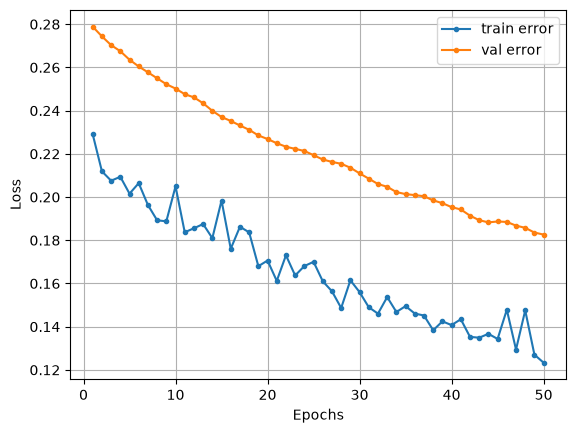

In [18]:
learning_curve(tr_loss_list, val_loss_list)

In [ ]:
# 학습된 모델 저장
# os.makedirs('results', exist_ok=True)
# torch.save(model.state_dict(), save_path)

#### Step 4. 모델 검증 평가

In [24]:
# pred 의 로짓값 출력
_, pred = evaluate(x_val_ts, y_val_ts, model, loss_fn, device)
print(pred.numpy()[:3])

# 로짓값을 softmax함수에 돌려서 범주별 확률값으로 변환
# pred = nn.functional.softmax(pred, dim=1)
# print(pred[:3])
pred = torch.softmax(pred, dim=1)
print(pred[:3])

# 가장 높은 확률값을 가진 인덱스 출력
pred = np.argmax(pred.numpy(), axis=1)
print(pred[:3])

[[-0.7098599   2.9589376  -2.0649178 ]
 [ 2.3413174   0.00912613 -2.644832  ]
 [ 2.3859231  -0.10783756 -2.5097213 ]]
tensor([[0.0247, 0.9689, 0.0064],
        [0.9059, 0.0879, 0.0062],
        [0.9174, 0.0758, 0.0069]])
[1 0 0]


In [28]:
print(confusion_matrix(y_val_ts.numpy(), pred))
print(classification_report(y_val_ts.numpy(), pred))
# print(classification_report(y_val_ts.numpy(), pred, target_names= le.classes_)) 
# le.classes_ 가 정수 값이므로 target_names 받을 수 없음

[[13  1  0]
 [ 0 15  1]
 [ 0  0  6]]
              precision    recall  f1-score   support

           0       1.00      0.93      0.96        14
           1       0.94      0.94      0.94        16
           2       0.86      1.00      0.92         6

    accuracy                           0.94        36
   macro avg       0.93      0.96      0.94        36
weighted avg       0.95      0.94      0.94        36



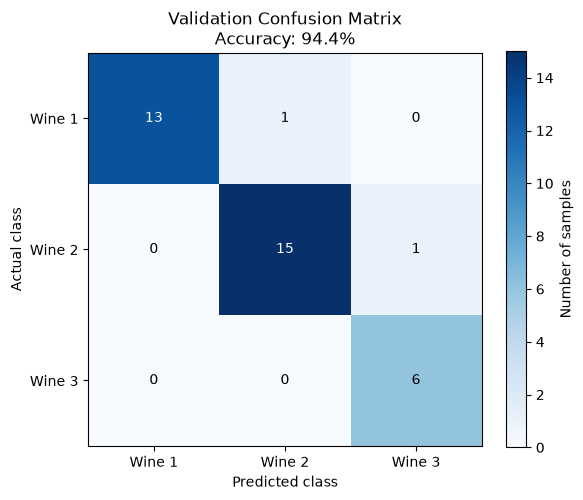

In [29]:
from sklearn.metrics import accuracy_score

# 1. 검증 데이터의 클래스별 점수(logits) 계산
_, logits = evaluate(
    x_val_ts, y_val_ts, model, loss_fn, device
)

# 2. 가장 높은 점수를 가진 클래스 선택
# 분류 결과만 필요하므로 Softmax를 거치지 않아도 됨
y_pred = logits.argmax(dim=1).cpu().numpy()
y_true = y_val_ts.cpu().numpy()

# 3. 혼동행렬과 정확도 계산
class_indices = np.arange(n_class)   # [0, 1, 2]
class_names = [
    f'Wine {original_class}' for original_class in le.classes_
]

cm = confusion_matrix(
    y_true, y_pred, labels=class_indices
)
accuracy = accuracy_score(y_true, y_pred)

# 4. 혼동행렬 시각화
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm, cmap='Blues')
fig.colorbar(im, ax=ax, label='Number of samples')

ax.set_xticks(class_indices)
ax.set_yticks(class_indices)
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)

ax.set_xlabel('Predicted class')
ax.set_ylabel('Actual class')
ax.set_title(f'Validation Confusion Matrix\nAccuracy: {accuracy:.1%}')

# 각 칸에 샘플 수 표시
for row in range(n_class):
    for col in range(n_class):
        ax.text(
            col, row, str(cm[row, col]),
            ha='center',
            va='center',
            color='white' if cm[row, col] > cm.max() / 2 else 'black'
        )

plt.tight_layout()
plt.show()

#### EX) 오분류 데이터 저장

In [30]:
# 오분류 여부
wrong_mask = y_true != y_pred

# 오분류 저장위치
# np.flatnonzero() | NumPy 배열을 1차원(1-D)으로 평탄화(Flatten)한 뒤, 
# 0이 아닌(Non-zero) 원소들의 인덱스를 1차원 배열 형태로 반환하는 함수
wrong_idx = np.flatnonzero(wrong_mask)

# 오분류 결과를 DataFrame으로 저장
wrong_results = pd.DataFrame({
    '검증데이터_위치': wrong_idx,
    '실제_클래스': le.inverse_transform(y_true[wrong_mask]),
    '예측_클래스': le.inverse_transform(y_pred[wrong_mask])
})

print(f'오분류: {len(wrong_results)} / {len(y_true)}개')
display(wrong_results)

오분류: 2 / 36개


,검증데이터_위치,실제_클래스,예측_클래스
0,23,2,3
1,33,1,2
